In [1]:
!unzip -q "/content/swinseg.zip" -d "/content/"

In [2]:

import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split

IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
IMAGE_DIR = '/content/swinseg/images'
MASK_DIR = '/content/swinseg/GTmaps'
OUTPUT_DIR = "/content/unet_swinseg_fixed_kernal_outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory in (IMAGE_DIR, MASK_DIR):
    if not os.path.isdir(directory):
        raise FileNotFoundError(
            f"Required dataset directory not found: {directory}"
        )

tf.keras.utils.set_random_seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

gpus = tf.config.list_physical_devices("GPU")

if not gpus:
    raise RuntimeError(
        "TensorFlow cannot detect a GPU. In Google Colab, "
        "select Runtime > Change runtime type > GPU."
    )

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow:", tf.__version__)
print("Visible GPUs:", gpus)
print("Images directory:", IMAGE_DIR)
print("Masks directory:", MASK_DIR)
print("Output directory:", OUTPUT_DIR)


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Images directory: /content/swinseg/images
Masks directory: /content/swinseg/GTmaps
Output directory: /content/unet_swinseg_fixed_kernal_outputs


In [4]:
def get_pairs(image_dir, mask_dir):
    valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    image_paths = sorted(
        os.path.join(image_dir, name)
        for name in os.listdir(image_dir)
        if os.path.splitext(name)[1].lower() in valid_exts
    )

    # Map masks using their corresponding image filename
    mask_map = {}

    for name in os.listdir(mask_dir):
        ext = os.path.splitext(name)[1].lower()

        if ext not in valid_exts:
            continue

        stem = os.path.splitext(name)[0]

        # Convert 001_GT to 001
        if stem.lower().endswith("_gt"):
            stem = stem[:-3]

        stem = stem.lower()
        mask_map[stem] = os.path.join(mask_dir, name)

    pairs = []

    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0].lower()

        if stem in mask_map:
            pairs.append((img_path, mask_map[stem]))
        else:
            print(f"Warning: no mask found for {img_path}")

    return pairs


pairs = get_pairs(IMAGE_DIR, MASK_DIR)

print("Total paired samples:", len(pairs))

for img, mask in pairs[:5]:
    print("Image:", os.path.basename(img))
    print("Mask: ", os.path.basename(mask))
    print()


def _decode_path(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    return os.fsdecode(path)


def load_image_mask(img_path, mask_path):
    img_path = _decode_path(img_path)
    mask_path = _decode_path(mask_path)
    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, IMG_SIZE, interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    threshold = 0 if mask.max(initial=0) <= 1 else 127
    mask = (mask > threshold).astype(np.float32)[..., np.newaxis]
    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)
    rotations = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    return tf.image.rot90(image, rotations), tf.image.rot90(mask, rotations)


def make_dataset(split_pairs, training=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")
    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(split_pairs), seed=SEED, reshuffle_each_iteration=True
        )
    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


pairs = get_pairs(IMAGE_DIR, MASK_DIR)
if len(pairs) < 10:
    raise ValueError(f"At least 10 paired images are required for an 80/10/10 split; found {len(pairs)}.")

train_pairs, holdout_pairs = train_test_split(
    pairs, test_size=0.30, random_state=SEED, shuffle=True
)
val_pairs, test_pairs = train_test_split(
    holdout_pairs, test_size=0.50, random_state=SEED, shuffle=True
)

split_pairs = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs,
}
split_keys = {
    name: {os.path.abspath(image_path) for image_path, _ in split}
    for name, split in split_pairs.items()
}
all_keys = {os.path.abspath(image_path) for image_path, _ in pairs}
if len(all_keys) != len(pairs):
    raise AssertionError("Duplicate image paths detected in the paired dataset.")
if any(split_keys[a] & split_keys[b] for a, b in (("train", "validation"), ("train", "test"), ("validation", "test"))):
    raise AssertionError("Data leakage detected between splits.")
if set().union(*split_keys.values()) != all_keys:
    raise AssertionError("The split does not cover every paired image exactly once.")
if sum(len(split) for split in split_pairs.values()) != len(pairs):
    raise AssertionError("Some paired samples were lost or duplicated during splitting.")

manifest_rows = [
    {
        "split": split_name,
        "image": image_path,
        "mask": mask_path,
        "image_filename": os.path.basename(image_path),
    }
    for split_name, split in split_pairs.items()
    for image_path, mask_path in sorted(split, key=lambda pair: pair[0])
]
manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)

print(f"Total paired images: {len(pairs)}")
for split_name, split in split_pairs.items():
    print(f"{split_name.title():12s}: {len(split):4d} images ({100 * len(split) / len(pairs):.2f}%)")
print(f"Saved split manifest: {manifest_path}")

Total paired samples: 115
Image: 001.jpg
Mask:  001_GT.jpg

Image: 002.jpg
Mask:  002_GT.jpg

Image: 003.jpg
Mask:  003_GT.jpg

Image: 004.jpg
Mask:  004_GT.jpg

Image: 005.jpg
Mask:  005_GT.jpg

Total paired images: 115
Train       :   80 images (69.57%)
Validation  :   17 images (14.78%)
Test        :   18 images (15.65%)
Saved split manifest: /content/unet_swinseg_fixed_kernal_outputs/dataset_split_manifest.csv


Model: "UNet_Binary_FixedKernel"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 256,  │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 256,  │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 256,  │      9,248 │ re_lu[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 128, 128,  │          0 │ re_lu_1[0][0]     │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128, 128,  │          0 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 128, 128,  │     18,496 │ dropout[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 128,  │     36,928 │ re_lu_2[0][0]     │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 64, 64,    │          0 │ re_lu_3[0][0]     │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_1[

 Total params: 8,903,873 (33.97 MB)

 Trainable params: 8,897,985 (33.94 MB)

 Non-trainable params: 5,888 (23.00 KB)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.7172 - dice_coef: 0.5261 - iou_coef: 0.3640 - loss: 0.4739
Epoch 1: val_dice_coef improved from None to 0.52629, saving model to /content/unet_swinseg_fixed_kernal_outputs/best_unet_fixedkernel.keras

Epoch 1: finished saving model to /content/unet_swinseg_fixed_kernal_outputs/best_unet_fixedkernel.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 63s 262ms/step - accuracy: 0.7835 - dice_coef: 0.6161 - iou_coef: 0.4539 - loss: 0.3839 - val_accuracy: 0.7644 - val_dice_coef: 0.5263 - val_iou_coef: 0.3619 - val_loss: 0.4718 - learning_rate: 1.0000e-04
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.8738 - dice_coef: 0.7592 - iou_coef: 0.6170 - loss: 0.2408
Epoch 2: val_dice_coef improved from 0.52629 to 0.58281, saving model to /content/unet_swinseg_fixed_kernal_outputs/best_unet_fixedkernel.keras

Epoch 2: finished saving model to /content/unet_swinseg_fixed_kernal_outputs/best_unet_fixedkernel.keras
40/40 ━━━━━━━━━━━━━━━━━

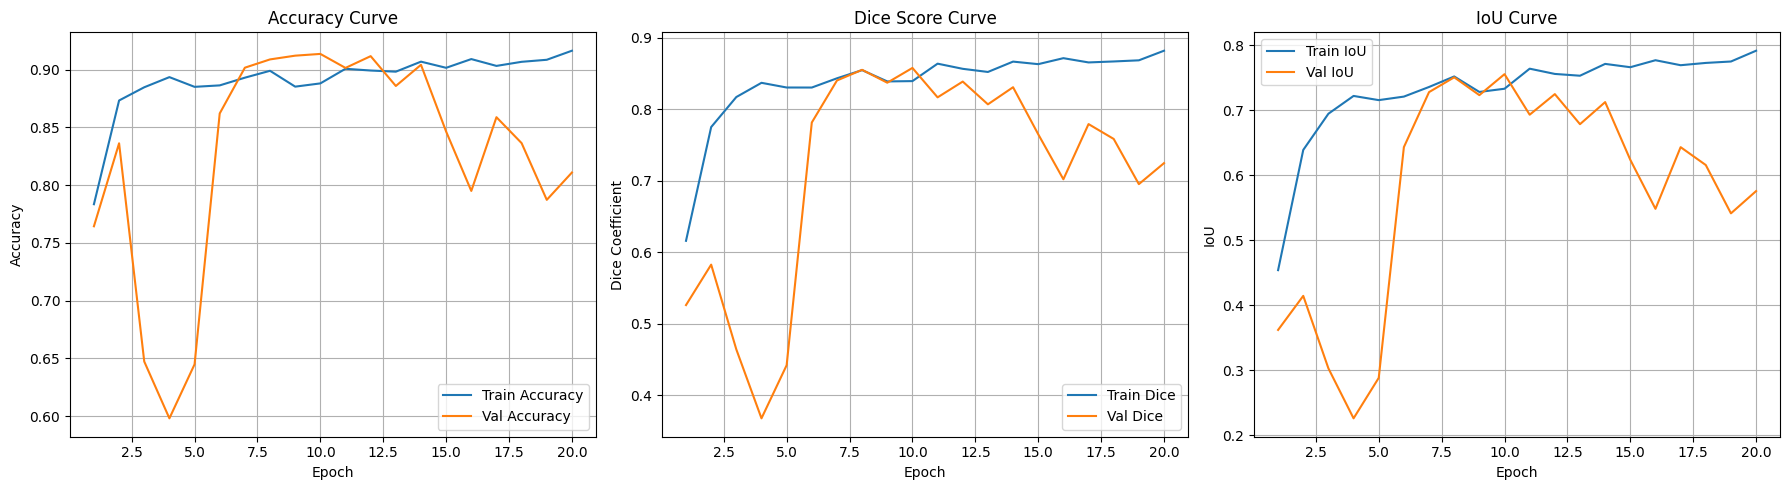

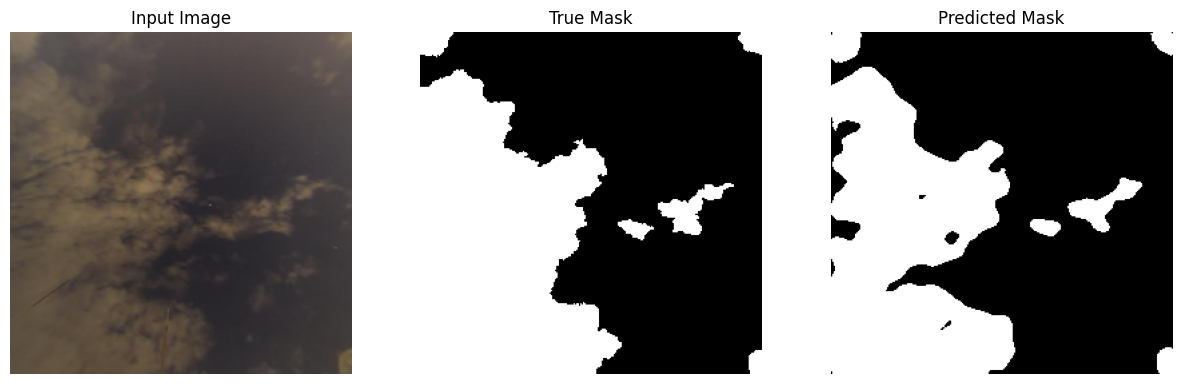

In [5]:
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

@tf.keras.utils.register_keras_serializable()
class FixedKernelLayer(layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(trainable=False, **kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])

        sobel_x = np.array([
            [-1, 0, 1],
            [-2, 0, 2],
            [-1, 0, 1]
        ], dtype=np.float32)

        sobel_y = np.array([
            [-1, -2, -1],
            [ 0,  0,  0],
            [ 1,  2,  1]
        ], dtype=np.float32)

        laplacian = np.array([
            [ 0,  1,  0],
            [ 1, -4,  1],
            [ 0,  1,  0]
        ], dtype=np.float32)

        def make_depthwise_kernel(base_kernel):
            k = np.zeros((3, 3, c, 1), dtype=np.float32)
            for ch in range(c):
                k[:, :, ch, 0] = base_kernel
            return tf.constant(k)

        self.k_sobel_x = make_depthwise_kernel(sobel_x)
        self.k_sobel_y = make_depthwise_kernel(sobel_y)
        self.k_lap = make_depthwise_kernel(laplacian)

        super().build(input_shape)

    def call(self, x):
        sx = tf.nn.depthwise_conv2d(
            x, self.k_sobel_x, strides=[1, 1, 1, 1], padding="SAME"
        )
        sy = tf.nn.depthwise_conv2d(
            x, self.k_sobel_y, strides=[1, 1, 1, 1], padding="SAME"
        )
        lp = tf.nn.depthwise_conv2d(
            x, self.k_lap, strides=[1, 1, 1, 1], padding="SAME"
        )
        return tf.concat([sx, sy, lp], axis=-1)

    def get_config(self):
        config = super().get_config()
        return config

def fixed_kernel_block(x):
    x = FixedKernelLayer()(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def merge_with_fixed_kernels(feat, filters, prefix):
    fk = FixedKernelLayer(name=f"{prefix}_fixed")(feat)
    x = layers.Concatenate(name=f"{prefix}_concat")([feat, fk])

    x = layers.Conv2D(
        filters,
        1,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{prefix}_compress"
    )(x)
    x = layers.ReLU(name=f"{prefix}_compress_relu")(x)
    return x

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x

def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p

def up_block(x, skip, skip_fixed, filters):
    x = layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = layers.Concatenate()([x, skip, skip_fixed])
    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x

def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    c1, p1 = down_block(inputs, 32)
    c2, p2 = down_block(p1, 64)
    c3, p3 = down_block(p2, 128)
    c4, p4 = down_block(p3, 256)

    c1_star = merge_with_fixed_kernels(c1, 32, "c1")
    c2_star = merge_with_fixed_kernels(c2, 64, "c2")
    c3_star = merge_with_fixed_kernels(c3, 128, "c3")
    c4_star = merge_with_fixed_kernels(c4, 256, "c4")

    bottleneck = conv_block(p4, 512)

    u1 = up_block(bottleneck, c4, c4_star, 256)
    u2 = up_block(u1, c3, c3_star, 128)
    u3 = up_block(u2, c2, c2_star, 64)
    u4 = up_block(u3, c1, c1_star, 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_Binary_FixedKernel")
    return model

model = build_unet()
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=["accuracy", dice_coef, iou_coef]
)

model.summary()

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        os.path.join(OUTPUT_DIR, "best_unet_fixedkernel.keras"),
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, "training_log.csv"))
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)
print("Model and logs saved under:", OUTPUT_DIR)

def plot_training_curves(history):
    hist = history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Val Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Val Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Val IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

plot_training_curves(history)

def show_prediction(model, pair):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.show()

show_prediction(model, val_pairs[0])


Loaded checkpoint weights: /content/unet_swinseg_fixed_kernal_outputs/best_unet_fixedkernel.keras
Prediction threshold: 0.5
Boundary tolerance: 2
Validation image 1/17: 005.jpg
Validation image 2/17: 041.jpg
Validation image 3/17: 031.jpg
Validation image 4/17: 070.jpg
Validation image 5/17: 079.jpg
Validation image 6/17: 032.jpg
Validation image 7/17: 016.jpg
Validation image 8/17: 101.jpg
Validation image 9/17: 013.jpg
Validation image 10/17: 106.jpg
Validation image 11/17: 094.jpg
Validation image 12/17: 071.jpg
Validation image 13/17: 095.jpg
Validation image 14/17: 010.jpg
Validation image 15/17: 067.jpg
Validation image 16/17: 019.jpg
Validation image 17/17: 045.jpg

VALIDATION METRICS — MACRO-AVERAGE OVER 17 IMAGES
IoU                     : 0.8141 ± 0.1210
Recall                  : 0.9042 ± 0.0857
Precision               : 0.9023 ± 0.1366
Dice Coefficient        : 0.8920 ± 0.0888
Boundary F1             : 0.6237 ± 0.1193
Boundary Recall         : 0.6061 ± 0.1001
Boundary Precisi

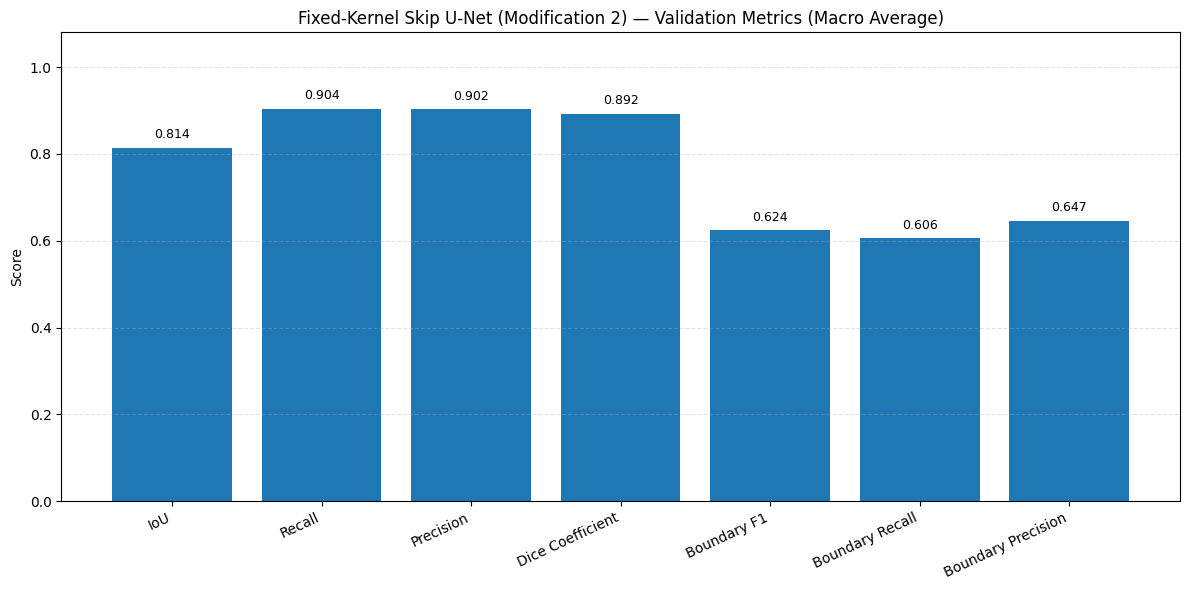

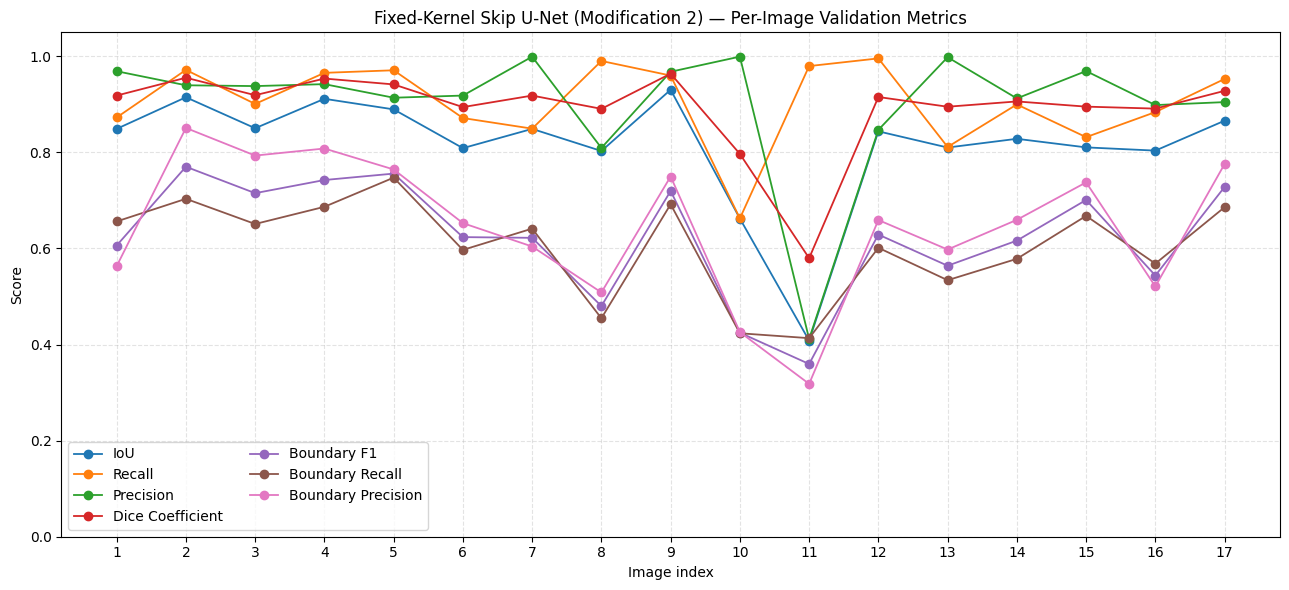

Saved macro-average plot: /content/unet_swinseg_fixed_kernal_outputs/validation_metrics_macro_average.png
Saved per-image plot: /content/unet_swinseg_fixed_kernal_outputs/validation_metrics_per_image.png
Test image 1/18: 110.jpg
Test image 2/18: 114.jpg
Test image 3/18: 068.jpg
Test image 4/18: 113.jpg
Test image 5/18: 001.jpg
Test image 6/18: 109.jpg
Test image 7/18: 054.jpg
Test image 8/18: 085.jpg
Test image 9/18: 048.jpg
Test image 10/18: 073.jpg
Test image 11/18: 012.jpg
Test image 12/18: 084.jpg
Test image 13/18: 082.jpg
Test image 14/18: 011.jpg
Test image 15/18: 027.jpg
Test image 16/18: 023.jpg
Test image 17/18: 046.jpg
Test image 18/18: 037.jpg

TEST METRICS — MACRO-AVERAGE OVER 18 IMAGES
IoU                     : 0.7879 ± 0.1454
Recall                  : 0.8632 ± 0.1717
Precision               : 0.9167 ± 0.0829
Dice Coefficient        : 0.8734 ± 0.1053
Boundary F1             : 0.5954 ± 0.1478
Boundary Recall         : 0.5885 ± 0.1536
Boundary Precision      : 0.6082 ± 0.144

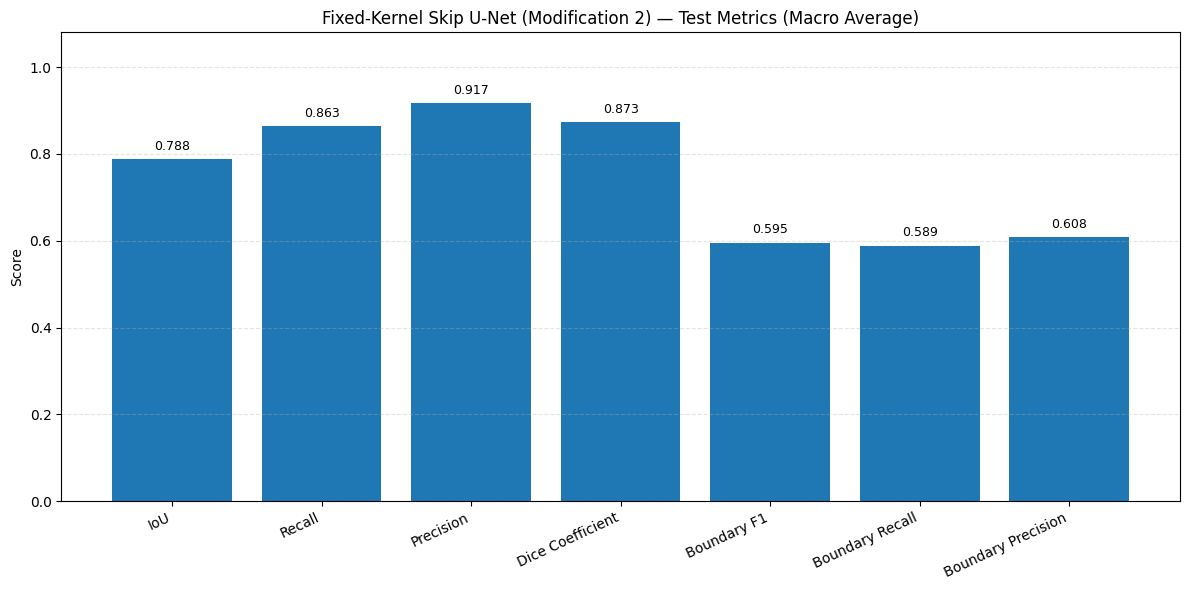

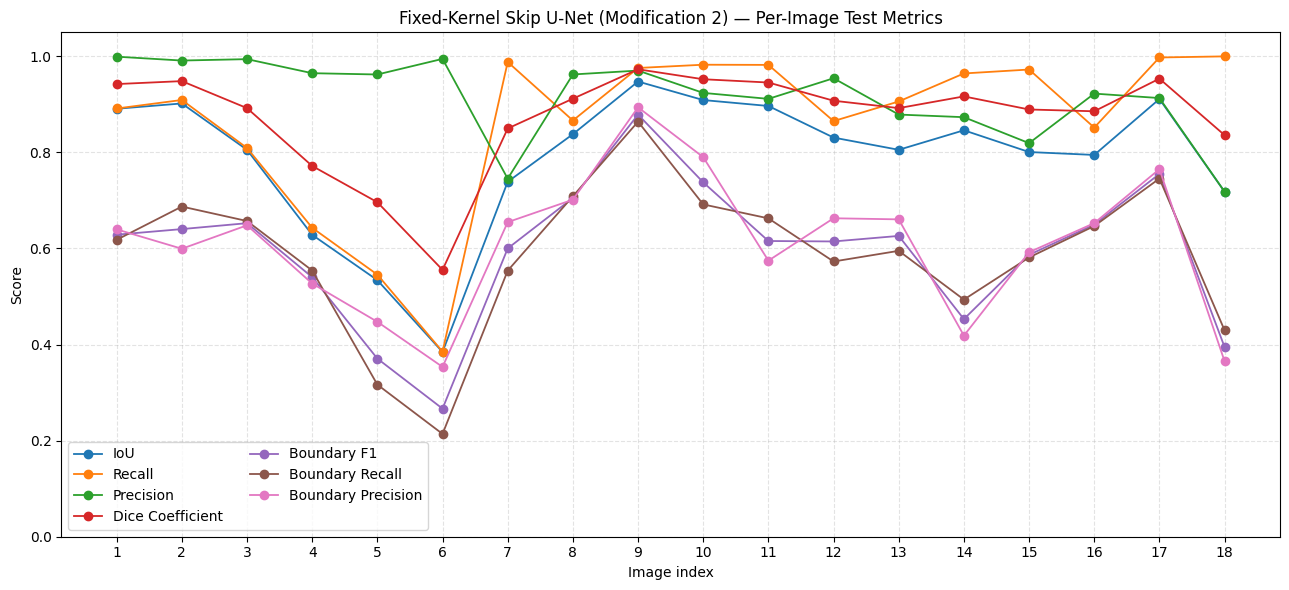

Saved macro-average plot: /content/unet_swinseg_fixed_kernal_outputs/test_metrics_macro_average.png
Saved per-image plot: /content/unet_swinseg_fixed_kernal_outputs/test_metrics_per_image.png

TEST EVALUATION COMPLETE.
Use the TEST summary for final held-out performance.
Keep validation results separate from test results.


In [6]:

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

PRED_THRESHOLD = float(globals().get("PRED_THRESHOLD", 0.5))
BOUNDARY_TOLERANCE = int(globals().get("BOUNDARY_TOLERANCE", 2))
BEST_MODEL_PATH = os.path.join(OUTPUT_DIR, "best_unet_fixedkernel.keras")

if not os.path.isfile(BEST_MODEL_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {BEST_MODEL_PATH}. Run training first."
    )

if "model" in globals() and isinstance(model, tf.keras.Model):
    best_model = model
elif "build_unet" in globals():
    best_model = build_unet(
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
    )
else:
    raise RuntimeError(
        "Run the model-building cell before evaluating the checkpoint."
    )

best_model.load_weights(BEST_MODEL_PATH)

print("Loaded checkpoint weights:", BEST_MODEL_PATH)
print("Prediction threshold:", PRED_THRESHOLD)
print("Boundary tolerance:", BOUNDARY_TOLERANCE)

METRIC_NAMES = [
    "iou",
    "recall",
    "precision",
    "dice_coef",
    "boundary_f1",
    "boundary_recall",
    "boundary_precision",
]

DISPLAY_NAMES = {
    "iou": "IoU",
    "recall": "Recall",
    "precision": "Precision",
    "dice_coef": "Dice Coefficient",
    "boundary_f1": "Boundary F1",
    "boundary_recall": "Boundary Recall",
    "boundary_precision": "Boundary Precision",
}

MODEL_DISPLAY_NAME = "Fixed-Kernel Skip U-Net (Modification 2)"


def _extract_boundary(mask):
    mask = (np.asarray(mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(
        mask,
        np.ones((3, 3), dtype=np.uint8),
        iterations=1,
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    return (mask - eroded).astype(np.uint8)


def _segmentation_metrics(gt_mask, pred_mask, tolerance=2):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)

    if gt.shape != pred.shape:
        raise ValueError(
            f"Mask shape mismatch: GT={gt.shape}, prediction={pred.shape}"
        )

    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))

    precision = tp / (tp + fp) if tp + fp else (
        1.0 if tp + fn == 0 else 0.0
    )
    recall = tp / (tp + fn) if tp + fn else (
        1.0 if tp + fp == 0 else 0.0
    )

    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn

    dice = 2 * tp / dice_den if dice_den else 1.0
    iou = tp / iou_den if iou_den else 1.0

    gt_boundary = _extract_boundary(gt)
    pred_boundary = _extract_boundary(pred)

    gt_count = int(gt_boundary.sum())
    pred_count = int(pred_boundary.sum())

    tolerance = max(0, int(tolerance))

    if tolerance > 0:
        kernel_size = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE,
            (kernel_size, kernel_size),
        )
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)
    else:
        gt_dilated = gt_boundary
        pred_dilated = pred_boundary

    matched_pred = int(
        np.sum((pred_boundary > 0) & (gt_dilated > 0))
    )
    matched_gt = int(
        np.sum((gt_boundary > 0) & (pred_dilated > 0))
    )

    boundary_precision = (
        matched_pred / pred_count
        if pred_count
        else (1.0 if gt_count == 0 else 0.0)
    )
    boundary_recall = (
        matched_gt / gt_count
        if gt_count
        else (1.0 if pred_count == 0 else 0.0)
    )

    boundary_sum = boundary_precision + boundary_recall
    boundary_f1 = (
        2 * boundary_precision * boundary_recall / boundary_sum
        if boundary_sum
        else 0.0
    )

    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


def evaluate_split(split_pairs, split_name, save_prediction_masks=False):
    if not split_pairs:
        raise ValueError(f"The {split_name} split is empty.")

    rows = []
    prediction_dir = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_predictions",
    )

    if save_prediction_masks:
        os.makedirs(prediction_dir, exist_ok=True)

    for idx, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, gt_mask = load_image_mask(
            os.fsencode(image_path),
            os.fsencode(mask_path),
        )

        pred_prob = best_model.predict(
            np.expand_dims(image, axis=0),
            verbose=0,
        )[0]

        pred_mask = (
            np.asarray(pred_prob).squeeze() >= PRED_THRESHOLD
        ).astype(np.uint8)

        gt_binary = (
            np.asarray(gt_mask).squeeze() > 0.5
        ).astype(np.uint8)

        scores = _segmentation_metrics(
            gt_binary,
            pred_mask,
            BOUNDARY_TOLERANCE,
        )

        rows.append({
            "image": os.path.basename(image_path),
            **scores,
        })

        if save_prediction_masks:
            out_name = (
                os.path.splitext(os.path.basename(image_path))[0]
                + "_pred.png"
            )
            output_path = os.path.join(prediction_dir, out_name)

            if not cv2.imwrite(output_path, pred_mask * 255):
                raise IOError(
                    f"Could not save prediction: {output_path}"
                )

        print(
            f"{split_name.title()} image "
            f"{idx}/{len(split_pairs)}: "
            f"{os.path.basename(image_path)}"
        )

    results_df = pd.DataFrame(rows)
    means = results_df[METRIC_NAMES].mean()

    stds = (
        results_df[METRIC_NAMES].std(ddof=1).fillna(0.0)
        if len(results_df) > 1
        else means * 0.0
    )

    print("\n" + "=" * 68)
    print(
        f"{split_name.upper()} METRICS — "
        f"MACRO-AVERAGE OVER {len(results_df)} IMAGES"
    )
    print("=" * 68)

    for metric in METRIC_NAMES:
        print(
            f"{DISPLAY_NAMES[metric]:<24}: "
            f"{means[metric]:.4f} ± {stds[metric]:.4f}"
        )

    print("=" * 68)

    summary_df = pd.DataFrame({
        "metric": [DISPLAY_NAMES[m] for m in METRIC_NAMES],
        "mean_score": [float(means[m]) for m in METRIC_NAMES],
        "std_score": [float(stds[m]) for m in METRIC_NAMES],
        "n_images": [len(results_df)] * len(METRIC_NAMES),
    })

    per_image_csv = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_metrics_per_image.csv",
    )
    summary_csv = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_metrics_summary.csv",
    )

    results_df.to_csv(per_image_csv, index=False)
    summary_df.to_csv(summary_csv, index=False)

    print("Saved per-image metrics:", per_image_csv)
    print("Saved summary metrics:", summary_csv)

    values = [float(means[m]) for m in METRIC_NAMES]
    labels = [DISPLAY_NAMES[m] for m in METRIC_NAMES]

    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, values)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title(
        f"{MODEL_DISPLAY_NAME} — "
        f"{split_name.title()} Metrics (Macro Average)"
    )
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.35)

    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.015,
            f"{value:.3f}",
            ha="center",
            va="bottom",
            fontsize=9,
        )

    plt.tight_layout()
    macro_plot = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_metrics_macro_average.png",
    )
    plt.savefig(macro_plot, dpi=200, bbox_inches="tight")
    plt.show()

    image_numbers = np.arange(1, len(results_df) + 1)

    plt.figure(figsize=(13, 6))

    for metric in METRIC_NAMES:
        plt.plot(
            image_numbers,
            results_df[metric],
            marker="o",
            linewidth=1.3,
            label=DISPLAY_NAMES[metric],
        )

    plt.ylim(0, 1.05)
    plt.xlabel("Image index")
    plt.ylabel("Score")
    plt.title(
        f"{MODEL_DISPLAY_NAME} — "
        f"Per-Image {split_name.title()} Metrics"
    )
    plt.xticks(image_numbers)
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(ncol=2)
    plt.tight_layout()

    per_image_plot = os.path.join(
        OUTPUT_DIR,
        f"{split_name}_metrics_per_image.png",
    )
    plt.savefig(per_image_plot, dpi=200, bbox_inches="tight")
    plt.show()

    print("Saved macro-average plot:", macro_plot)
    print("Saved per-image plot:", per_image_plot)

    return results_df, summary_df


if "load_image_mask" not in globals():
    raise RuntimeError(
        "Run the data-loading cell defining load_image_mask() first."
    )

if "val_pairs" not in globals() or "test_pairs" not in globals():
    raise RuntimeError(
        "Run the dataset-splitting cell defining val_pairs and test_pairs first."
    )

validation_results, validation_summary = evaluate_split(
    val_pairs,
    "validation",
    save_prediction_masks=False,
)

test_results, test_summary = evaluate_split(
    test_pairs,
    "test",
    save_prediction_masks=True,
)

print("\nTEST EVALUATION COMPLETE.")
print("Use the TEST summary for final held-out performance.")
print("Keep validation results separate from test results.")
